## Setup Imports

In [8]:
from monai.utils import first, set_determinism
from monai.transforms import (
    AsDiscrete,
    AsDiscreted,
    EnsureChannelFirstd,
    Compose,
    CropForegroundd,
    LoadImaged,
    Orientationd,
    RandCropByPosNegLabeld,
    SaveImaged,
    ScaleIntensityRanged,
    Spacingd,
    Invertd,
)
from monai.handlers.utils import from_engine
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.metrics import DiceMetric
from monai.losses import DiceLoss
from monai.inferers import sliding_window_inference
from monai.data import CacheDataset, DataLoader, Dataset, decollate_batch
from monai.config import print_config
from monai.apps import download_and_extract
import torch
import matplotlib.pyplot as plt
import tempfile
import shutil
import os
import glob
import torch
import nibabel as nib
from sklearn.model_selection import train_test_split

print("All core dependencies loaded cleanly.")

All core dependencies loaded cleanly.


## Setup dataset paths

In [29]:
#For this early stage we will only be using the short axis (SAX) images, as the 2CH and 4CH images will be used during the Multi-View stage.

from pathlib import Path

data_dir = Path("../../data/CINE_MULTI")

def get_data_dict(view: str, split: str) -> list[dict[str, str]]:
    folder = data_dir / f"{view}_{split.upper()}"
    images = sorted(folder.glob("image/*.nii.gz"))
    labels = sorted(folder.glob("anno/*.nii.gz"))
    
    assert len(images) == len(labels), f"Mismatch in {folder}: {len(images)} images vs {len(labels)} labels"
    return [{"image": str(img), "label": str(lbl)} for img, lbl in zip(images, labels)]

# Generate the dictionaries
data_dict_SAX_train = get_data_dict("SAX", "TR")
data_dict_SAX_val   = get_data_dict("SAX", "VAL")

data_dict_2CH_train = get_data_dict("2CH", "TR")
data_dict_2CH_val   = get_data_dict("2CH", "VAL")

data_dict_4CH_train = get_data_dict("4CH", "TR")
data_dict_4CH_val   = get_data_dict("4CH", "VAL")



#No need for cross validation, as MICCAI dataset includes its own testing set, at a 7:1 ratio of training to testing data.
#Snippet left in, just in case

#Setting up cross validation
#train_files, val_files = train_test_split(
#    data_dict_SAX,
#    test_size=0.20,  # 20% held out for validation
#    random_state=42,  # Fixed seed ensures identical split across runs
#    shuffle=True,
#)

print(f"Training cases:   {len(data_dict_SAX_train)}")
print(f"Validation cases: {len(data_dict_SAX_val)}")

Training cases:   105
Validation cases: 15


In [30]:
#For reproducibility and deterministic behaviour
set_determinism(seed=0)

## Setup transforms for training and validation

Here we use several transforms to augment the dataset:
1. `LoadImaged` loads the spleen CT images and labels from NIfTI format files.
1. `EnsureChannelFirstd` ensures the original data to construct "channel first" shape.
1. `Orientationd` unifies the data orientation based on the affine matrix.
1. `Spacingd` adjusts the spacing by `pixdim=(1.5, 1.5, 2.)` based on the affine matrix.
1. `ScaleIntensityRanged` extracts intensity range [-57, 164] and scales to [0, 1].
1. `CropForegroundd` removes all zero borders to focus on the valid body area of the images and labels.
1. `RandCropByPosNegLabeld` randomly crop patch samples from big image based on pos / neg ratio.  
The image centers of negative samples must be in valid body area.
1. `RandAffined` efficiently performs `rotate`, `scale`, `shear`, `translate`, etc. together based on PyTorch affine transform.

In [51]:
train_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        # ScaleIntensityRanged(
        #     keys=["image"],
        #     a_min=-57,
        #     a_max=164,
        #     b_min=0.0,
        #     b_max=1.0,
        #     clip=True,
        # ),
        # CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
        Orientationd(keys=["image", "label"], axcodes="RAS"),
        # Spacingd(keys=["image", "label"], pixdim=(1.5, 1.5, 2.0), mode=("bilinear", "nearest")),
        # RandCropByPosNegLabeld(
        #     keys=["image", "label"],
        #     label_key="label",
        #     spatial_size=(96, 96, 96),
        #     pos=1,
        #     neg=1,
        #     num_samples=4,
        #     image_key="image",
        #     image_threshold=0,
        # ),
        # user can also add other random transforms
        # RandAffined(
        #     keys=['image', 'label'],
        #     mode=('bilinear', 'nearest'),
        #     prob=1.0, spatial_size=(96, 96, 96),
        #     rotate_range=(0, 0, np.pi/15),
        #     scale_range=(0.1, 0.1, 0.1)),
    ]
)
val_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        # ScaleIntensityRanged(
        #     keys=["image"],
        #     a_min=-57,
        #     a_max=164,
        #     b_min=0.0,
        #     b_max=1.0,
        #     clip=True,
        # ),
        # CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
        Orientationd(keys=["image", "label"], axcodes="RAS"),
        # Spacingd(keys=["image", "label"], pixdim=(1.5, 1.5, 2.0), mode=("bilinear", "nearest")),
    ]
)

## Check transforms in DataLoader

image shape: torch.Size([149, 250, 144]), label shape: torch.Size([149, 250, 144])


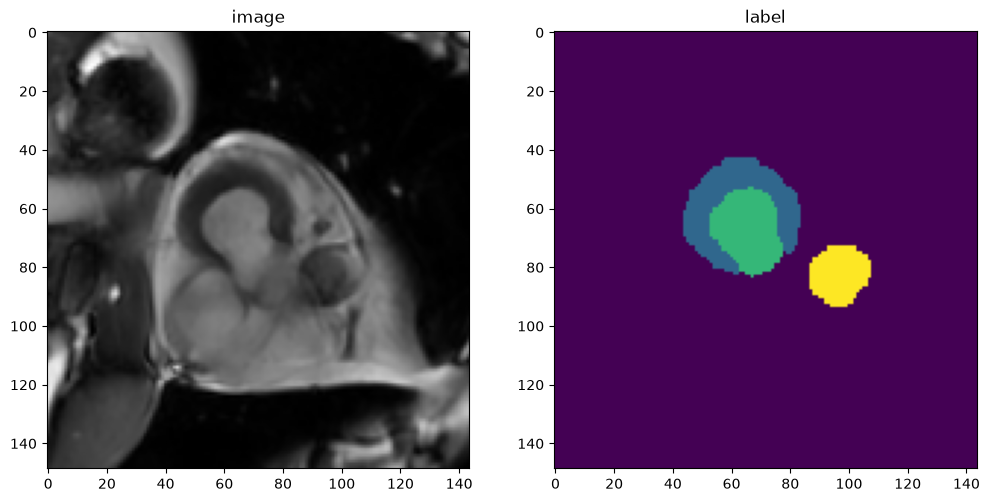

In [52]:
check_ds = Dataset(data=val_files, transform=val_transforms)
check_loader = DataLoader(check_ds, batch_size=1)
check_data = first(check_loader)
image, label = (check_data["image"][0][0], check_data["label"][0][0])
print(f"image shape: {image.shape}, label shape: {label.shape}")
# plot the slice [:, :, 80]
plt.figure("check", (12, 6))
plt.subplot(1, 2, 1)
plt.title("image")
plt.imshow(image[:, 40, :], cmap="gray")
plt.subplot(1, 2, 2)
plt.title("label")
plt.imshow(label[:, 40, :])
plt.show()

## Define CacheDataset and DataLoader for training and validation

Here we use CacheDataset to accelerate training and validation process, it's 10x faster than the regular Dataset.  
To achieve best performance, set `cache_rate=1.0` to cache all the data, if memory is not enough, set lower value.  
Users can also set `cache_num` instead of `cache_rate`, will use the minimum value of the 2 settings.  
And set `num_workers` to enable multi-threads during caching.  
If want to to try the regular Dataset, just change to use the commented code below.

In [ ]:
train_ds = CacheDataset(data=train_files, transform=train_transforms, cache_rate=1.0, num_workers=4)
# train_ds = Dataset(data=train_files, transform=train_transforms)

# use batch_size=2 to load images and use RandCropByPosNegLabeld
# to generate 2 x 4 images for network training
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=4)

val_ds = CacheDataset(data=val_files, transform=val_transforms, cache_rate=1.0, num_workers=4)
# val_ds = Dataset(data=val_files, transform=val_transforms)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=4)

## Create Model, Loss, Optimiser

In [12]:
# standard PyTorch program style: create UNet, DiceLoss and Adam optimizer
device = torch.device("cuda:0" if torch.cuda.device_count() > 0 else "cpu")
model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=2,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm=Norm.BATCH,
).to(device)
loss_function = DiceLoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.Adam(model.parameters(), 1e-4)
dice_metric = DiceMetric(include_background=False, reduction="mean")